In [ ]:
pip install statsmodels

In [3]:
from pathlib import Path

RAW_PATH = Path("datasets/raw/a10.csv").resolve()

PROJECT_ROOT = Path.cwd().resolve().parent
RAW_PATH = PROJECT_ROOT / "datasets" / "raw" / "a10.csv"

print(RAW_PATH)

D:\TimeSeries_Data\total_practice\Practice_2\datasets\raw\a10.csv


# **Bài 1: Khám phá dữ liệu (EDA)**

In [16]:
import pandas as pd

df = pd.read_csv(RAW_PATH)

# Chuyển cột date sang datetime
df["date"] = pd.to_datetime(df["date"], errors="raise")

# Đặt date làm index
df = df.set_index("date").sort_index()

# Đảm bảo monthly frequency
df = df.asfreq("MS")

print(df.head())

               value
date                
1991-07-01  3.526591
1991-08-01  3.180891
1991-09-01  3.252221
1991-10-01  3.611003
1991-11-01  3.565869


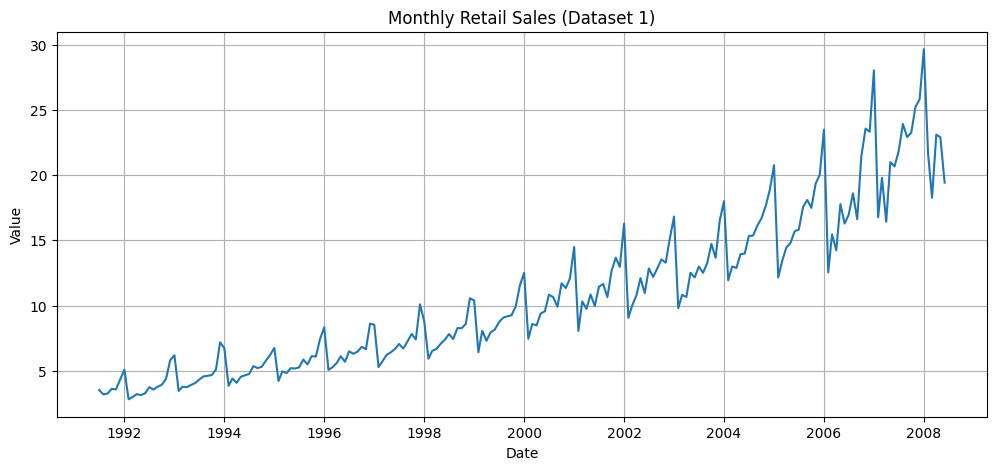

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['value'])
plt.title("Monthly Retail Sales (Dataset 1)")
plt.xlabel("Date")
plt.ylabel("Value")
plt.grid(True)
plt.show()

# **Bài 2: Kiểm định ADF trên chuỗi gốc**

In [68]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df['value'])
print(f"ADF Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4f}")

ADF Statistic: 3.1452
p-value: 1.0000


C:\Users\PC\AppData\Local\Temp\ipykernel_10472\2327418335.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['value'])


#### ***Với chuỗi gốc của a10.csv, p-value > 0.05 (thậm chí bằng 1.0), nên kết luận chuỗi gốc KHÔNG dừng.***

# **Bài 3: Sai phân & Kiểm định lại**

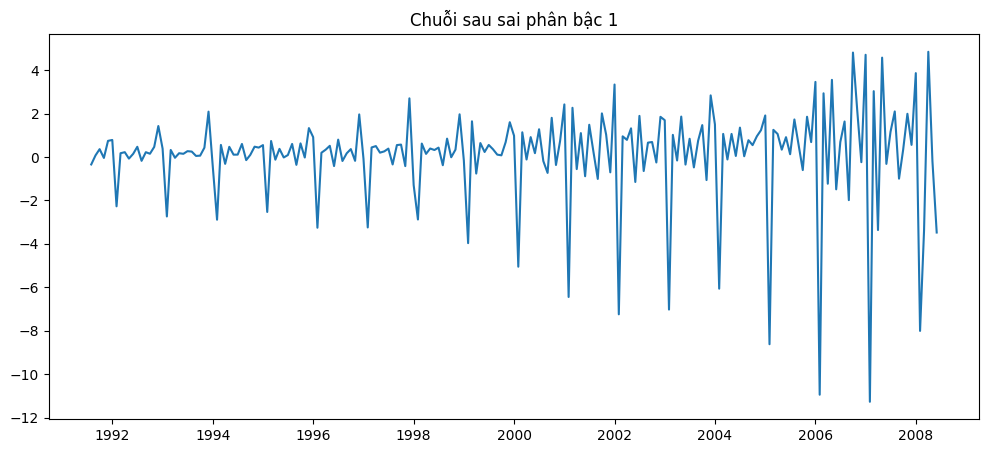

ADF Statistic (Diff 1): -2.4952
p-value (Diff 1): 0.116653


C:\Users\PC\AppData\Local\Temp\ipykernel_10472\3542891253.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res_diff1 = adfuller(df_diff1)


In [23]:
from statsmodels.tsa.stattools import adfuller
df_diff1 = df['value'].diff().dropna()

plt.figure(figsize=(12, 5))
plt.plot(df_diff1)
plt.title("Chuỗi sau sai phân bậc 1")
plt.show()

res_diff1 = adfuller(df_diff1)
print(f"ADF Statistic (Diff 1): {res_diff1[0]:.4f}")
print(f"p-value (Diff 1): {res_diff1[1]:.6f}")

# **Bài 4: Phân tích ACF & PACF**

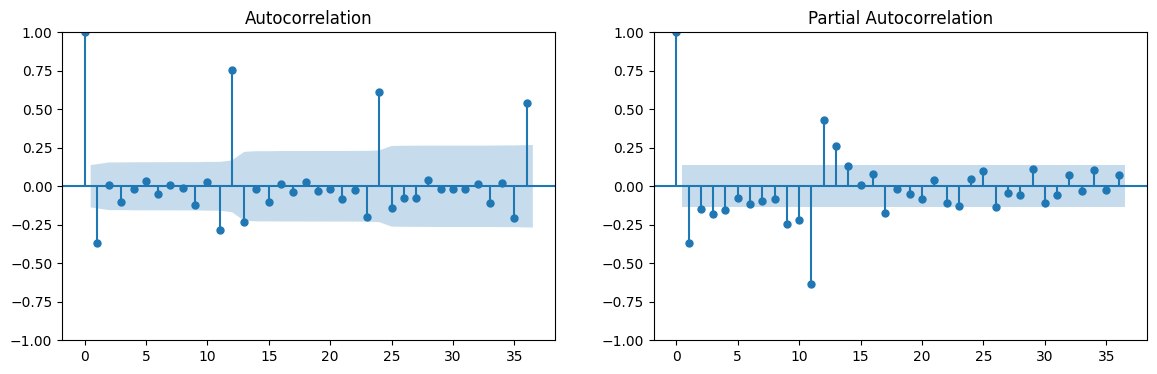

In [24]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df_diff1, lags=36, ax=axes[0])
plot_pacf(df_diff1, lags=36, ax=axes[1], method='ywm')
plt.show()

### **ACF cắt cụt ở lag nào?**
- Biểu đồ ACF bị cắt cụt sau Lag 1 $\rightarrow$ q = 1 (đồng thời có các spike mùa vụ tại lag 12, 24, 36)
### **PACF cắt cụt ở lag nào?** 
- Biểu đồ PACF cắt cụt sau Lag 4 $\rightarrow p = 4$ (trong đó tương quan mạnh nhất nằm ở Lag 1 $\rightarrow$ có thể xét $p = 1$ hoặc $p = 2$ để mô hình tinh gọn)
### **Gợi ý mô hình ARIMA(p,d,q)?**
- Kết hợp với sai phân bậc 1 ($d = 1$), đề xuất thử nghiệm các mô hình ARIMA: ARIMA(4, 1, 1), ARIMA(1, 1, 1) hoặc ARIMA(2, 1, 1). Đồng thời, do chuỗi có các spike mùa vụ rất mạnh tại chu kỳ s = 12, đề xuất thêm mô hình SARIMA: SARIMA(1, 1, 1, 12)

# **Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá**

In [25]:
# 1. Chia Train (80%) - Test (20%) theo đúng thứ tự thời gian
train_size = int(len(df) * 0.8)
train, test = df['value'].iloc[:train_size], df['value'].iloc[train_size:]

In [28]:
from statsmodels.tsa.arima.model import ARIMA

# 2. Huấn luyện mô hình ARIMA(1,1,1) và ARIMA(2,1,1)
model1 = ARIMA(train, order=(1, 1, 1))
fitted_model1 = model1.fit()
print(f"ARIMA(1,1,1) - AIC: {fitted_model1.aic:.2f} | BIC: {fitted_model1.bic:.2f}")

model2 = ARIMA(train, order=(2, 1, 1))
fitted_model2 = model2.fit()
print(f"ARIMA(2,1,1) - AIC: {fitted_model2.aic:.2f} | BIC: {fitted_model2.bic:.2f}")

ARIMA(1,1,1) - AIC: 582.47 | BIC: 591.73
ARIMA(2,1,1) - AIC: 584.46 | BIC: 596.81


**Chọn ARIMA(1,1,1) vì có AIC và BIC thấp nhất, cho thấy mô hình đạt được sự cân bằng tốt hơn giữa độ chính xác và độ phức tạp.**

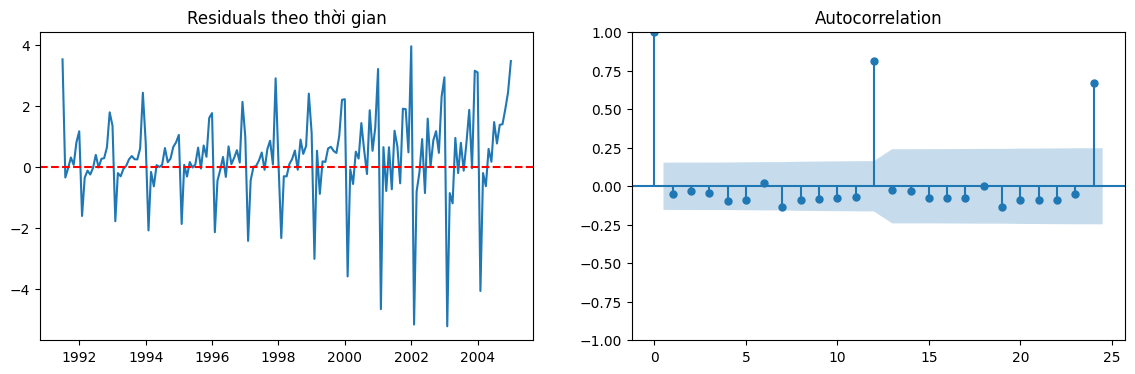

In [29]:
# 3. Chẩn đoán phần dư (Residual Diagnostics)
residuals = fitted_model1.resid
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(residuals)
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_title("Residuals theo thời gian")
plot_acf(residuals, lags=24, ax=ax[1])
plt.show()

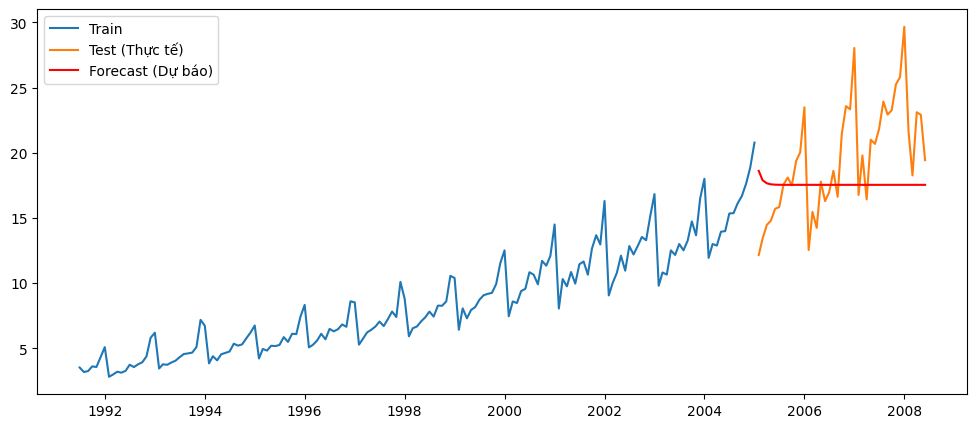

In [30]:
# 4. Dự báo trên tập Test
forecast = fitted_model1.forecast(steps=len(test))

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Test (Thực tế)')
plt.plot(test.index, forecast, label='Forecast (Dự báo)', color='red')
plt.legend()
plt.show()

In [34]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 5. Tính các chỉ số đánh giá MAE, RMSE, MAPE
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = np.mean(np.abs((test - forecast) / test)) * 100
print(f"MAE: {mae:.3f} | RMSE: {rmse:.3f} | MAPE: {mape:.2f}%")

MAE: 3.667 | RMSE: 4.624 | MAPE: 18.04%


### **1. Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?**
- Không được shuffle (xáo trộn) vì: Dữ liệu chuỗi thời gian có tính phụ thuộc chặt chẽ vào trình tự thời gian trước - sau (quá khứ quyết định hiện tại, hiện tại quyết định tương lai). Việc shuffle sẽ làm đứt gãy cấu trúc tự tương quan ở các độ trễ (lags) và gây ra hiện tượng rò rỉ dữ liệu từ tương lai về quá khứ (Data Leakage) trong quá trình huấn luyện.
- Vai trò của Test set: Tập Test (20% dữ liệu cuối từ năm 2005 đến 2008) đóng vai trò là dữ liệu tương lai chưa từng được nhìn thấy, dùng để kiểm tra và đánh giá khách quan khả năng dự báo thực tế (khả năng tổng quát hóa) của mô hình.
### **2. Ý nghĩa của p, d, q đã chọn?**
Mô hình được lựa chọn là ARIMA(1, 1, 1) do có chỉ số AIC (582.47) và BIC (591.73) thấp hơn so với ARIMA(2, 1, 1) (AIC: 584.46 BIC: 596.81). Ý nghĩa từng tham số: 
- p = 1 (AR(1)): giá trị hiện tại cuả chuỗi chịu ảnh hưởng trực tiếp bởi giá trị của chính nó ở 1 tháng ngay trước đó (lag = 1)
- d = 1: chuỗi gốc được lấy sai phân bậc 1 để đưa chuỗi về trạng thái dừng.
- q = 1 (MA(1)): giá trị hiện tại của chuỗi chịu ảnh hưởng bởi sai số dự báo của 1 tháng ngay trước đó (lag = 1)
### **3. Mô hình có hội tụ không?**
- Có hội tụ. Quá trình ước lượng hợp lý cực đại (MLE) khi chạy lệnh .fit() cho cả hai mô hình ARIMA(1,1,1) và ARIMA(2,1,1) đã hoàn tất nhanh chóng mà không xuất hiện cảnh báo lỗi không hội tụ (ConvergenceWarning), đồng thời tính toán thành công các hệ số và chỉ số AIC, BIC.
### **4. Residuals có phải white noise không?**
- Không, Residuals chưa phải white noise.
- Vì biểu đồ ACF của residuals vẫn xuất hiện các đỉnh vượt khỏi khoảng tin cậy tại các lag 12 và 24, cho thấy residuals vẫn còn tự tương quan và dấu hiệu mùa vụ.
### **5. Nếu residuals còn tự tương quan → điều chỉnh gì?**
- Cần điều chỉnh tham số p hoặc q, hoặc sử dụng mô hình SARIMA để mô hình hóa thành phần mùa vụ còn sót lại.
### **6. Dự đoán có bám sát xu hướng không?**
- Không bám sát. Quan sát trên đồ thị dự báo, đường Forecast (màu đỏ) chỉ giảm nhẹ ở bước đầu tiên rồi nhanh chóng đi ngang thành một đường thẳng cố định quanh mức giá trị **$\approx 17.6$17.6**. Mô hình hoàn toàn không bắt được đà tăng trưởng tiếp tục đi lên (Trend) cũng như các nhịp dao động lên xuống theo mùa vụ (Seasonality) của tập Test thực tế (màu cam) trong giai đoạn 2005–2008.
### **Sai lệch lớn nhất xảy ra ở đâu?**
- Sai lệch lớn nhất xảy ra tại các đỉnh cao của tập test, khoảng năm 2007-2008, khi giá trị thực tế gần 30 nhưng mô hình chỉ dự báo quanh mức 18.
### **Chỉ số nào nhạy với outlier nhất?**
- RMSE nhạy với outlier nhất vì sai số được bình phương trước khi tính toán, làm cho các sai số lớn có ảnh hưởng rất mạnh đến kết quả.
### **RMSE lớn hay nhỏ nói lên điều gì?**
- RMSE càng nhỏ thì dự báo càng gần giá trị thực tế và mô hình càng chính xác. RMSE lớn cho thấy sai số dự báo lớn và mô hình mô tả dữ liệu chưa tốt. Với RMSE = 4.624, mô hình vẫn còn sai lệch đáng kể so với dữ liệu thực tế.

# **BÀI TẬP NÂNG CAO: Mô hình SARIMA với Dataset 2**

### **Load dữ liệu & Vẽ chuỗi thời gian**

In [53]:
from pathlib import Path

RAW_PATH2 = Path("datasets/raw/airline-passengers.csv").resolve()

PROJECT_ROOT = Path.cwd().resolve().parent
RAW_PATH2 = PROJECT_ROOT / "datasets" / "raw" / "airline-passengers.csv"

print(RAW_PATH2)

D:\TimeSeries_Data\total_practice\Practice_2\datasets\raw\airline-passengers.csv


In [56]:
import pandas as pd

df2 = pd.read_csv(RAW_PATH2, parse_dates=['Month'], index_col='Month')
df2.head()

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


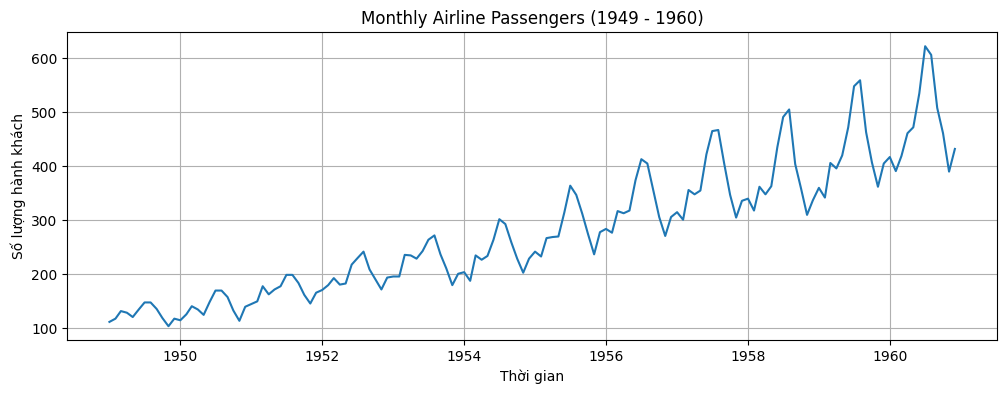

In [64]:
plt.figure(figsize=(12, 4))
plt.plot(df2.index, df2['Passengers'], color='tab:blue')
plt.title("Monthly Airline Passengers (1949 - 1960)")
plt.xlabel("Thời gian")
plt.ylabel("Số lượng hành khách")
plt.grid(True)
plt.show()

#### *Nhận xét: Chuỗi có xu hướng tăng rõ rệt và có tính mùa vụ lặp lại theo chu kỳ s = 12 tháng*

### **Kiểm định ADF trên chuỗi gốc -> Chứng minh không dừng**

In [66]:
adf_orig = adfuller(df2['Passengers'])
print(f"ADF Statistic: {adf_orig[0]:.4f} | p-value: {adf_orig[1]:.4f}")
print("-> Kết luận: p-value > 0.05 => Chấp nhận H0, chuỗi gốc KHÔNG DỪNG.\n")

ADF Statistic: 0.8154 | p-value: 0.9919
-> Kết luận: p-value > 0.05 => Chấp nhận H0, chuỗi gốc KHÔNG DỪNG.



C:\Users\PC\AppData\Local\Temp\ipykernel_10472\797446843.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_orig = adfuller(df2['Passengers'])


### **Sai phân thường + mùa vụ**

In [48]:
# Sai phân thường (d=1) kết hợp sai phân mùa vụ (D=1, s=12)
df2_diff = df2['Passengers'].diff(1).diff(12).dropna()
print("p-value sau sai phân kép:", adfuller(df2_diff)[1])

p-value sau sai phân kép: 1.8565116001234705e-28


C:\Users\PC\AppData\Local\Temp\ipykernel_10472\3918148872.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("p-value sau sai phân kép:", adfuller(df2_diff)[1])


### **Biểu đồ ACF/PACF**

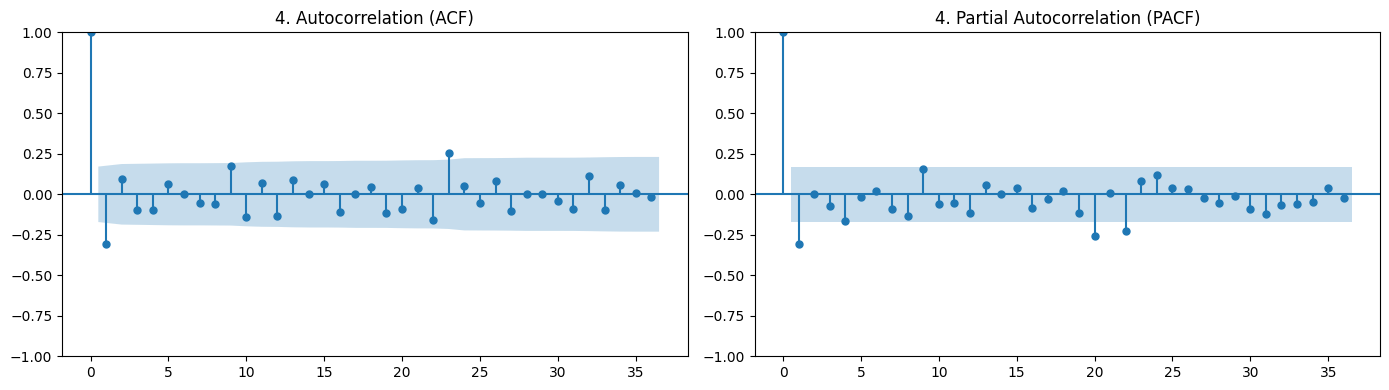

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df2_diff, lags=36, ax=axes[0], title="Autocorrelation (ACF)")
plot_pacf(df2_diff, lags=36, ax=axes[1], method='ywm', title="Partial Autocorrelation (PACF)")
plt.tight_layout()

#### ***Thành phần ngắn hạn (p, q): Cả hai biểu đồ ACF và PACF đều có 1 spike âm vượt ngưỡng tin cậy rõ rệt nhất tại lag 1 $\rightarrow$ p = 1, q = 1***
#### ***Thành phần mùa vụ (P, Q) tại chu kỳ s = 12: Tại các độ trễ mùa vụ lag 12, 24, 36, các cột trên cả ACF và PACF đều đã nằm trong vùng tin cậy ,chứng tỏ sai phân mùa vụ D = 1 đã loại bỏ tốt tính chu kỳ $\rightarrow$ P = 0, Q = 0 hoặc P = 1, Q = 1 (để tinh chỉnh phần tương quan nhỏ còn sót lại ở lag 12).***

# **Chia Train/Test & Fit mô hình SARIMA**

In [ ]:
# Chia Train/Test (80/20)
n_train = int(len(df2) * 0.8)
train2, test2 = df2['Passengers'].iloc[:n_train], df2['Passengers'].iloc[n_train:]

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Fit và dự báo với SARIMA trên Dataset 2
sarima_model = SARIMAX(train2, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
sarima_fit = sarima_model.fit(disp=False)
sarima_pred = sarima_fit.forecast(steps=len(test2))

mae_sarima = mean_absolute_error(test2, sarima_pred)
rmse_sarima = np.sqrt(mean_squared_error(test2, sarima_pred))
mape_sarima = np.mean(np.abs((test2 - sarima_pred) / test2)) * 100

# 2. Fit và dự báo với ARIMA(1,1,1) trên Dataset 2
arima_model2 = ARIMA(train2, order=(1, 1, 1))
arima_fit2 = arima_model2.fit()
arima_pred2 = arima_fit2.forecast(steps=len(test2))

mae_arima2 = mean_absolute_error(test2, arima_pred2)
rmse_arima2 = np.sqrt(mean_squared_error(test2, arima_pred2))
mape_arima2 = np.mean(np.abs((test2 - arima_pred2) / test2)) * 100

c:\Users\PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\PC\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\PC\AppData\Local\Programs\Python\Python311\Lib\site-package

In [61]:
# Chỉ số đánh giá
print(f"ARIMA(1,1,1)            MAE: {mae_arima2:6.2f} | RMSE: {rmse_arima2:6.2f} | MAPE: {mape_arima2:5.2f}%")
print(f"SARIMA(1,1,1)(1,1,1)12  MAE: {mae_sarima:6.2f} | RMSE: {rmse_sarima:6.2f} | MAPE: {mape_sarima:5.2f}%")

ARIMA(1,1,1)            MAE:  85.25 | RMSE:  97.50 | MAPE: 21.29%
SARIMA(1,1,1)(1,1,1)12  MAE:  23.56 | RMSE:  30.14 | MAPE:  5.05%


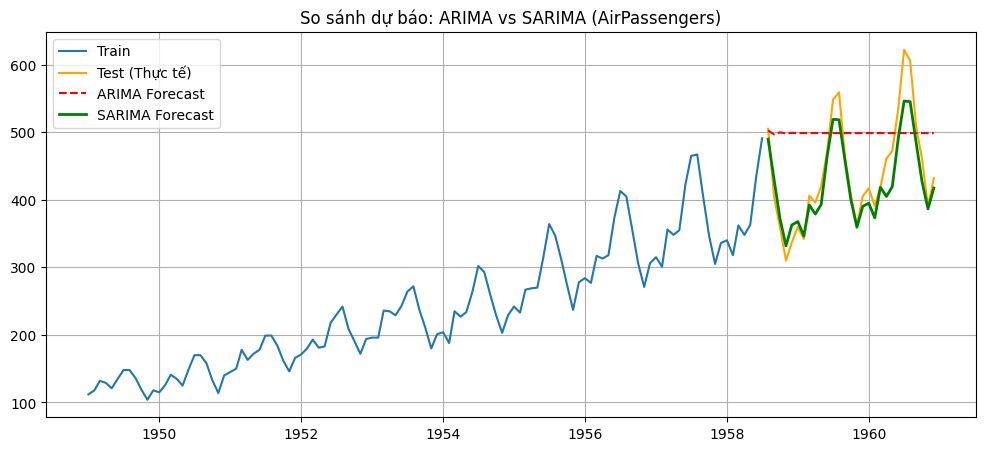

In [62]:
#Vẽ biểu đồ so sánh trực quan ARIMA vs SARIMA
plt.figure(figsize=(12, 5))
plt.plot(train2.index, train2, label='Train')
plt.plot(test2.index, test2, label='Test (Thực tế)', color='orange')
plt.plot(test2.index, arima_pred2, label='ARIMA Forecast', color='red', linestyle='--')
plt.plot(test2.index, sarima_pred, label='SARIMA Forecast', color='green', linewidth=2)
plt.title("So sánh dự báo: ARIMA vs SARIMA (AirPassengers)")
plt.legend()
plt.grid(True)
plt.show()

#### **Nhận xét và So sánh giữa ARIMA và SARIMA:**
- **Mô hình ARIMA:** Hoàn toàn thất bại trong việc nắm bắt tính mùa vụ và xu hướng dài hạn. Đường dự báo bị phẳng (đi ngang ở mức 498 ngay từ đỉnh cuối của tập Train), dẫn đến sai số rất lớn ở cả các vùng đáy thấp điểm lẫn các đỉnh cao điểm trong giai đoạn 1958–1960. 
- **Mô hình SARIMA:** Thể hiện sự vượt trội hoàn toàn khi bám sát cả xu hướng tăng trưởng lẫn chu kỳ dao động mùa vụ 12 tháng của tập dữ liệu thực tế (đường cam). Các điểm đảo chiều (đỉnh mùa hè và đáy mùa đông) đều khớp chính xác về mặt thời gian.